In [1]:
##########################
# RDE NUMERICAL SOLUTION #
##########################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np 

In [2]:
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
b1 = kappa1*theta1
epsilon1 = -kappa1

kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
b2 = kappa2*theta2
epsilon2 = -kappa2

def funVasicek(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2+(1/2)*sigma1**2*beta1**2+(1/2)*sigma2**2*beta2**2, epsilon1*beta1-1, epsilon2*beta2-1]
def funCIR(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2, epsilon1*beta1+(1/2)*sigma1**2*beta1**2-1, epsilon2*beta2+(1/2)*sigma2**2*beta2**2-1]

U_0 = [0, 0, 0]
t_pts = np.linspace(0, 10, 11)
resultVasicek = solve_ivp(funVasicek, (0, 10), U_0, t_eval=t_pts, method='RK45')

U_0 = [0, 0, 0]
t_pts = np.linspace(0, 10, 11)
resultCIR = solve_ivp(funCIR, (0, 10), U_0, t_eval=t_pts, method='RK45')

resultVasicek, resultCIR

(  message: 'The solver successfully reached the end of the integration interval.'
      nfev: 62
      njev: 0
       nlu: 0
       sol: None
    status: 0
   success: True
         t: array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])
  t_events: None
         y: array([[ 0.        , -0.15756962, -0.52434511, -1.0035023 , -1.54479142,
         -2.12158378, -2.71809852, -3.32649961, -3.94153923, -4.56037643,
         -5.18163147],
        [ 0.        , -0.752042  , -1.16469653, -1.39116122, -1.51567464,
         -1.58347721, -1.62125786, -1.64156334, -1.65275758, -1.65908957,
         -1.66236531],
        [ 0.        , -0.78696794, -1.26425539, -1.55374235, -1.72946291,
         -1.83572248, -1.90054142, -1.93954786, -1.96325109, -1.97775944,
         -1.98638789]])
  y_events: None,
   message: 'The solver successfully reached the end of the integration interval.'
      nfev: 68
      njev: 0
       nlu: 0
       sol: None
    status: 0
   success: True
         t: array

In [3]:
###########################
# SWAPTION EXERCISE BOUND #
###########################

# Consider swaption given by t=0, S=5, T=10 and yearly cashflows in between

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np

In [161]:
#ATMF strike Vasicek + sanity check

VasPtT1 = np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*0.05+resultVasicek.y[2,1]*0.05)
VasPtT2 = np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*0.05+resultVasicek.y[2,2]*0.05)
VasPtT3 = np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*0.05+resultVasicek.y[2,3]*0.05)
VasPtT4 = np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*0.05+resultVasicek.y[2,4]*0.05)
VasPtS = np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*0.05+resultVasicek.y[2,5]*0.05)
VasPtT6 = np.exp(resultVasicek.y[0,6]+resultVasicek.y[1,6]*0.05+resultVasicek.y[2,6]*0.05)
VasPtT7 = np.exp(resultVasicek.y[0,7]+resultVasicek.y[1,7]*0.05+resultVasicek.y[2,7]*0.05)
VasPtT8 = np.exp(resultVasicek.y[0,8]+resultVasicek.y[1,8]*0.05+resultVasicek.y[2,8]*0.05)
VasPtT9 = np.exp(resultVasicek.y[0,9]+resultVasicek.y[1,9]*0.05+resultVasicek.y[2,9]*0.05)
VasPtT = np.exp(resultVasicek.y[0,10]+resultVasicek.y[1,10]*0.05+resultVasicek.y[2,10]*0.05)

VasATMFSwapK = (VasPtS - VasPtT)/(VasPtT6 + VasPtT7 + VasPtT8 + VasPtT9 + VasPtT)
KVasicek = VasATMFSwapK+0.2*VasATMFSwapK
VasATMFSwapK, VasPtS-KVasicek*VasPtT6-KVasicek*VasPtT7-KVasicek*VasPtT8-KVasicek*VasPtT9-(1+KVasicek)*VasPtT

(0.8377629312333242, -0.019265474916965192)

In [162]:
#ATMF strike CIR + sanity check

CIRPtT1 = np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*0.05+resultCIR.y[2,1]*0.05)
CIRPtT2 = np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*0.05+resultCIR.y[2,2]*0.05)
CIRPtT3 = np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*0.05+resultCIR.y[2,3]*0.05)
CIRPtT4 = np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*0.05+resultCIR.y[2,4]*0.05)
CIRPtS = np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*0.05+resultCIR.y[2,5]*0.05)
CIRPtT6 = np.exp(resultCIR.y[0,6]+resultCIR.y[1,6]*0.05+resultCIR.y[2,6]*0.05)
CIRPtT7 = np.exp(resultCIR.y[0,7]+resultCIR.y[1,7]*0.05+resultCIR.y[2,7]*0.05)
CIRPtT8 = np.exp(resultCIR.y[0,8]+resultCIR.y[1,8]*0.05+resultCIR.y[2,8]*0.05)
CIRPtT9 = np.exp(resultCIR.y[0,9]+resultCIR.y[1,9]*0.05+resultCIR.y[2,9]*0.05)
CIRPtT = np.exp(resultCIR.y[0,10]+resultCIR.y[1,10]*0.05+resultCIR.y[2,10]*0.05)

CIRATMFSwapK = (CIRPtS - CIRPtT)/(CIRPtT6 + CIRPtT7 + CIRPtT8 + CIRPtT9 + CIRPtT)
KCIR = CIRATMFSwapK+0.2*CIRATMFSwapK
CIRATMFSwapK, CIRPtS-KCIR*CIRPtT6-KCIR*CIRPtT7-KCIR*CIRPtT8-KCIR*CIRPtT9-(1+KCIR)*CIRPtT

(0.9299859409740431, -0.016735423777645635)

In [6]:
#################################################
# FETCH QUANTILES FROM RESPECTIVE DISTRIBUTIONS #
#################################################

from scipy.stats import norm
import numpy as np
from scipy.stats import ncx2

In [7]:
#Vasicek 1st factor distr.

r0 = 0.05
expiryT = 5
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
EV1 = r0*np.exp(-kappa1*expiryT)+theta1*(1-np.exp(-kappa1*expiryT))
Var1 = (sigma1**2/kappa1)*(1-np.exp(-2*kappa1*expiryT))
lowerquantile1 = norm.ppf((1-0.9545)/2, loc=EV1, scale=Var1)
upperquantile1 = norm.ppf((1+0.9545)/2, loc=EV1, scale=Var1)

Var1, (lowerquantile1, EV1, upperquantile1)

(0.06650141652155558,
 (0.249571530505351, 0.38257452607124764, 0.5155775216371442))

In [8]:
#Vasicek 2nd factor distr.

r0 = 0.05
expiryT = 5
kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
EV2 = r0*np.exp(-kappa2*expiryT)+theta2*(1-np.exp(-kappa2*expiryT))
Var2 = (sigma2**2/kappa2)*(1-np.exp(-2*kappa2*expiryT))
lowerquantile2 = norm.ppf((1-0.9545)/2, loc=EV2, scale=Var2)
upperquantile2 = norm.ppf((1+0.9545)/2, loc=EV2, scale=Var2)

Var2, (lowerquantile2, EV2, upperquantile2)

(0.019865241060018295,
 (0.23974821967533397, 0.2794787503440253, 0.3192092810127166))

In [9]:
#CIR 1st factor distr.

r01 = 0.05
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
expiryT = 5
dt = expiryT - 0

mu1 = 4 * theta1 * kappa1 / sigma1**2
ncx2_init1 = r01
non_central1 = 4 * kappa1 * np.exp(-kappa1 * dt) / (sigma1**2 * (1 - np.exp(-kappa1 * dt))) * ncx2_init1
scale1 = sigma1**2 * (1-np.exp(-kappa1 * dt)) / (4 * kappa1)
X_1_new = ncx2(df=mu1,nc=non_central1,scale=scale1)
EV1newCIR = (mu1+non_central1)*scale1

X_1_new.ppf(0.5), X_1_new.var(), (X_1_new.ppf((1-0.9545)/2), EV1newCIR, X_1_new.ppf((1+0.9545)/2))

(0.3720023453599923,
 0.012196422593183173,
 (0.19487952478665166, 0.38257452607124764, 0.6336219896108802))

In [10]:
#CIR 2nd factor distr.

r02 = 0.05
kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
expiryT = 5
dt = expiryT - 0

mu2 = 4 * theta2 * kappa2 / sigma2**2
ncx2_init2 = r02
non_central2 = 4 * kappa2 * np.exp(-kappa2 * dt) / (sigma2**2 * (1 - np.exp(-kappa2 * dt))) * ncx2_init2
scale2 = sigma2**2 * (1-np.exp(-kappa2 * dt)) / (4 * kappa2)
X_2_new = ncx2(df=mu2,nc=non_central2,scale=scale2)
EV2newCIR = (mu2+non_central2)*scale2

X_2_new.ppf(0.5), X_2_new.var(), (X_2_new.ppf((1-0.9545)/2), EV2newCIR, X_2_new.ppf((1+0.9545)/2))

(0.2763809054033594,
 0.002603050900878677,
 (0.1870085832617806, 0.27947875034402525, 0.39052671495758956))

In [11]:
################################
# PLUG Y_S INTO EXERCISE BOUND #
################################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
import numpy as np

In [163]:
# Solve P(x)-1=0 <=> P(x)=1

VasEnd1ExerciseBound = lambda Y1S1 : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S1+resultVasicek.y[2,1]*lowerquantile2)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*Y1S1+resultVasicek.y[2,2]*lowerquantile2)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*Y1S1+resultVasicek.y[2,3]*lowerquantile2)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*Y1S1+resultVasicek.y[2,4]*lowerquantile2)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*Y1S1+resultVasicek.y[2,5]*lowerquantile2)-1
VasY1S1_init_guess = 0.2
VasSolY1S1 = fsolve(VasEnd1ExerciseBound, VasY1S1_init_guess)

VasEnd2ExerciseBound = lambda Y1S2 : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S2+resultVasicek.y[2,1]*upperquantile2)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*Y1S2+resultVasicek.y[2,2]*upperquantile2)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*Y1S2+resultVasicek.y[2,3]*upperquantile2)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*Y1S2+resultVasicek.y[2,4]*upperquantile2)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*Y1S2+resultVasicek.y[2,5]*upperquantile2)-1
VasY1S2_init_guess = 0.2
VasSolY1S2 = fsolve(VasEnd2ExerciseBound, VasY1S2_init_guess)

x = [VasSolY1S1[0],VasSolY1S2[0]]
y = [lowerquantile2, upperquantile2]

#slope coef[0], intercept coef[1]

coefVas = np.polyfit(y,x,1)

(VasSolY1S1[0],VasSolY1S2[0]), (lowerquantile2, upperquantile2), coefVas, KVasicek

((0.497026056236313, 0.41039509908874305),
 (0.23974821967533397, 0.3192092810127166),
 array([-1.09023156,  0.75840713]),
 1.005315517479989)

In [164]:
# Solve P(x)-1=0 <=> P(x)=1

CIREnd1ExerciseBound = lambda Y1S1 : 1-KCIR*np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*Y1S1+resultCIR.y[2,1]*X_2_new.ppf((1-0.9545)/2))-KCIR*np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*Y1S1+resultCIR.y[2,2]*X_2_new.ppf((1-0.9545)/2))-KCIR*np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*Y1S1+resultCIR.y[2,3]*X_2_new.ppf((1-0.9545)/2))-KCIR*np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*Y1S1+resultCIR.y[2,4]*X_2_new.ppf((1-0.9545)/2))-(1+KCIR)*np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*Y1S1+resultCIR.y[2,5]*X_2_new.ppf((1-0.9545)/2))
CIRY1S1_init_guess = 0.2
CIRSolY1S1 = fsolve(CIREnd1ExerciseBound, CIRY1S1_init_guess)

CIREnd2ExerciseBound = lambda Y1S2 : 1-KCIR*np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*Y1S2+resultCIR.y[2,1]*X_2_new.ppf((1+0.9545)/2))-KCIR*np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*Y1S2+resultCIR.y[2,2]*X_2_new.ppf((1+0.9545)/2))-KCIR*np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*Y1S2+resultCIR.y[2,3]*X_2_new.ppf((1+0.9545)/2))-KCIR*np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*Y1S2+resultCIR.y[2,4]*X_2_new.ppf((1+0.9545)/2))-(1+KCIR)*np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*Y1S2+resultCIR.y[2,5]*X_2_new.ppf((1+0.9545)/2))
CIRY1S2_init_guess = 0.2
CIRSolY1S2 = fsolve(CIREnd2ExerciseBound, CIRY1S2_init_guess)

CIRx = [CIRSolY1S1[0],CIRSolY1S2[0]]
CIRy = [X_2_new.ppf((1-0.9545)/2), X_2_new.ppf((1+0.9545)/2)]

#slope coef[0], intercept coef[1]

coefCIR = np.polyfit(CIRy,CIRx,1)

(CIRSolY1S1[0], CIRSolY1S2[0]), (X_2_new.ppf((1-0.9545)/2), X_2_new.ppf((1+0.9545)/2)), X_2_new.ppf(0.5), coefCIR, KCIR

((0.6305684013303687, 0.4066698313523597),
 (0.1870085832617806, 0.39052671495758956),
 0.2763809054033594,
 array([-1.10014065,  0.83630415]),
 1.1159831291688518)

In [47]:
#Don H. Kim's Taylor approximation

import sympy as sp

In [165]:
Vas3ExerciseBound = lambda Y1S3 : 1-KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*Y1S3+resultVasicek.y[2,1]*EV2)-KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*Y1S3+resultVasicek.y[2,2]*EV2)-KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*Y1S3+resultVasicek.y[2,3]*EV2)-KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*Y1S3+resultVasicek.y[2,4]*EV2)-(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*Y1S3+resultVasicek.y[2,5]*EV2)
VasY1S3_init_guess = 0.2
VasSolY1S3 = fsolve(Vas3ExerciseBound, VasY1S3_init_guess)

x, y = sp.symbols('x y')
VasPrimeX = sp.diff(1-KVasicek*sp.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*x+resultVasicek.y[2,1]*y)-KVasicek*sp.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*x+resultVasicek.y[2,2]*y)-KVasicek*sp.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*x+resultVasicek.y[2,3]*y)-KVasicek*sp.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*x+resultVasicek.y[2,4]*y)-(1+KVasicek)*sp.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*x+resultVasicek.y[2,5]*y), x)
VasPrimeY = sp.diff(1-KVasicek*sp.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*x+resultVasicek.y[2,1]*y)-KVasicek*sp.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*x+resultVasicek.y[2,2]*y)-KVasicek*sp.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*x+resultVasicek.y[2,3]*y)-KVasicek*sp.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*x+resultVasicek.y[2,4]*y)-(1+KVasicek)*sp.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*x+resultVasicek.y[2,5]*y), y)
VasSlopeTaylor1 = float(VasPrimeX.evalf(subs={x: VasSolY1S3[0], y: EV2}))
VasSlopeTaylor2 = float(VasPrimeY.evalf(subs={x: VasSolY1S3[0], y: EV2}))
VasInterceptTaylor = VasSlopeTaylor1*VasSolY1S3[0]+VasSlopeTaylor2*EV2
VasSolY1S3[0], VasSlopeTaylor1, VasSlopeTaylor2, VasInterceptTaylor

(0.4537091058820082,
 1.0439830633803775,
 1.1381832770896507,
 0.7917626621857541)

In [24]:
-VasSlopeTaylor2/VasSlopeTaylor1, VasInterceptTaylor/VasSlopeTaylor1

(-1.0930152542888276, 0.5931088819698053)

In [ ]:
#Hence b=(0.36819935552167765, 0.4348546274004361) and a=0.22743940815267769
#Sanity checks : 

In [25]:
Vas4ExerciseBound = lambda Y1S4 : VasSlopeTaylor1*Y1S4+VasSlopeTaylor2*lowerquantile2 - VasInterceptTaylor
VasY1S4_init_guess = 0.2
VasSolY1S4 = fsolve(Vas4ExerciseBound, VasY1S4_init_guess)
VasSolY1S4[0], VasSolY1S1[0]

(0.3310604206760764, 0.3310619286393963)

In [26]:
Vas5ExerciseBound = lambda Y1S5 : VasSlopeTaylor1*Y1S5+VasSlopeTaylor2*upperquantile2 - VasInterceptTaylor
VasY1S5_init_guess = 0.2
VasSolY1S5 = fsolve(Vas5ExerciseBound, VasY1S5_init_guess)
VasSolY1S5[0], VasSolY1S2[0]

(0.244208268512337, 0.24420977581838274)

In [166]:
#Repeat for CIR
CIR3ExerciseBound = lambda Y1S3 : 1-KCIR*np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*Y1S3+resultCIR.y[2,1]*EV2newCIR)-KCIR*np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*Y1S3+resultCIR.y[2,2]*EV2newCIR)-KCIR*np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*Y1S3+resultCIR.y[2,3]*EV2newCIR)-KCIR*np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*Y1S3+resultCIR.y[2,4]*EV2newCIR)-(1+KCIR)*np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*Y1S3+resultCIR.y[2,5]*EV2newCIR)
CIRY1S3_init_guess = 0.2
CIRSolY1S3 = fsolve(CIR3ExerciseBound, CIRY1S3_init_guess)

x, y = sp.symbols('x y')
CIRPrimeX = sp.diff(1-KCIR*sp.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*x+resultCIR.y[2,1]*y)-KCIR*sp.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*x+resultCIR.y[2,2]*y)-KCIR*sp.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*x+resultCIR.y[2,3]*y)-KCIR*sp.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*x+resultCIR.y[2,4]*y)-(1+KCIR)*sp.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*x+resultCIR.y[2,5]*y), x)
CIRPrimeY = sp.diff(1-KCIR*sp.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*x+resultCIR.y[2,1]*y)-KCIR*sp.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*x+resultCIR.y[2,2]*y)-KCIR*sp.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*x+resultCIR.y[2,3]*y)-KCIR*sp.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*x+resultCIR.y[2,4]*y)-(1+KCIR)*sp.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*x+resultCIR.y[2,5]*y), y)
CIRSlopeTaylor1 = float(CIRPrimeX.evalf(subs={x: CIRSolY1S3[0], y: EV2newCIR}))
CIRSlopeTaylor2 = float(CIRPrimeY.evalf(subs={x: CIRSolY1S3[0], y: EV2newCIR}))
CIRInterceptTaylor = CIRSlopeTaylor1*CIRSolY1S3[0]+CIRSlopeTaylor2*EV2newCIR
CIRSolY1S3[0], CIRSlopeTaylor1, CIRSlopeTaylor2, CIRInterceptTaylor

(0.5288244251035271,
 1.0099554692827146,
 1.1111181093455527,
 0.8446230211081056)

In [28]:
#Check hvad der sker ved normalisering til b1=1 ... versus (-1.10331198,  0.66385198)
-CIRSlopeTaylor2/CIRSlopeTaylor1, CIRInterceptTaylor/CIRSlopeTaylor1

(-1.1033277963750454, 0.6638462443889087)

In [29]:
CIR4ExerciseBound = lambda Y1S4 : CIRSlopeTaylor1*Y1S4+CIRSlopeTaylor2*X_2_new.ppf((1-0.9545)/2) - CIRInterceptTaylor
CIRY1S4_init_guess = 0.2
CIRSolY1S4 = fsolve(CIR4ExerciseBound, CIRY1S4_init_guess)
CIRSolY1S4[0], CIRSolY1S1[0]

(0.45751447631546904, 0.45752631120695025)

In [30]:
CIR5ExerciseBound = lambda Y1S5 : CIRSlopeTaylor1*Y1S5+CIRSlopeTaylor2*X_2_new.ppf((1+0.9545)/2) - CIRInterceptTaylor
CIRY1S5_init_guess = 0.2
CIRSolY1S5 = fsolve(CIR5ExerciseBound, CIRY1S5_init_guess)
CIRSolY1S5[0], CIRSolY1S2[0]

(0.2329672645491659, 0.23298430040887225)

In [81]:
##################
#Residuals + plots 
import matplotlib.pyplot as plt

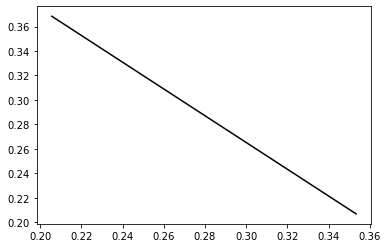

In [197]:
ApproxEBVasicek = lambda x: -(VasSlopeTaylor2/VasSlopeTaylor1)*x+VasInterceptTaylor/VasSlopeTaylor1
x = np.linspace(norm.ppf(1-0.9999, loc=EV2, scale=Var2),norm.ppf(0.9999, loc=EV2, scale=Var2), 10000)
plt.plot(x, ApproxEBVasicek(x),color='k')

In [199]:
EBVasicekPoints[0], EBVasicekPoints[9999], ApproxEBVasicek(x), EBVasicekPoints[5000], ApproxEBVasicek(x)[5000]

(0.36839060749477726,
 0.2068885077689955,
 array([0.36838539, 0.36836924, 0.36835309, ..., 0.2069156 , 0.20689945,
        0.2068833 ]),
 0.2876262686818928,
 0.28762626868184044)

In [200]:
EBVasicek = lambda z : KVasicek*np.exp(resultVasicek.y[0,1]+resultVasicek.y[1,1]*z+resultVasicek.y[2,1]*w)+KVasicek*np.exp(resultVasicek.y[0,2]+resultVasicek.y[1,2]*z+resultVasicek.y[2,2]*w)+KVasicek*np.exp(resultVasicek.y[0,3]+resultVasicek.y[1,3]*z+resultVasicek.y[2,3]*w)+KVasicek*np.exp(resultVasicek.y[0,4]+resultVasicek.y[1,4]*z+resultVasicek.y[2,4]*w)+(1+KVasicek)*np.exp(resultVasicek.y[0,5]+resultVasicek.y[1,5]*z+resultVasicek.y[2,5]*w)-1
VasEB_init_guess = 0.2
EBVasicekPoints = []
for i in range(len(x)):
    w = x[i]
    sol = fsolve(EBVasicek, VasEB_init_guess)[0]
    EBVasicekPoints.append(sol)

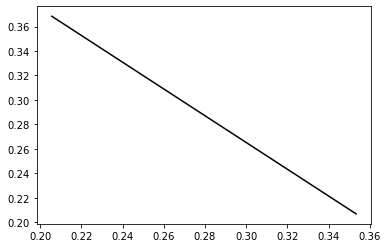

In [201]:
plt.plot(x, EBVasicekPoints,color='k')

(-2.5e-07, 1.75e-06)

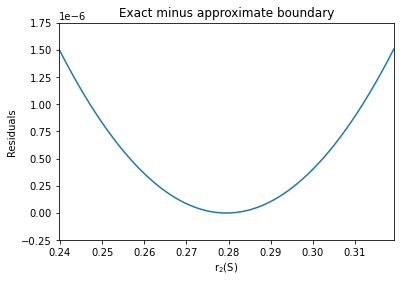

In [202]:
residualsVasicek = []
for i in range(len(EBVasicekPoints)):
    diff = EBVasicekPoints[i]-ApproxEBVasicek(x)[i]
    residualsVasicek.append(diff)
plt.plot(x,residualsVasicek)
plt.ylabel('Residuals')
plt.xlabel('r$_2$(S)')
plt.title('Exact minus approximate boundary')
plt.xlim(norm.ppf((1-0.9545)/2, loc=EV2, scale=Var2), norm.ppf((1+0.9545)/2, loc=EV2, scale=Var2))
plt.ylim(-0.25*10**(-6), 1.75*10**(-6))

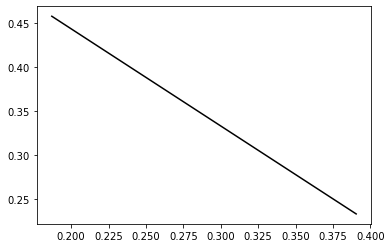

In [82]:
ApproxEBCIR = lambda x: -(CIRSlopeTaylor2/CIRSlopeTaylor1)*x+CIRInterceptTaylor/CIRSlopeTaylor1
x2 = np.linspace(X_2_new.ppf((1-0.9545)/2),X_2_new.ppf((1+0.9545)/2), 10000)
plt.plot(x2, ApproxEBCIR(x2),color='k')

In [83]:
EBCIR = lambda z : 1-KCIR*np.exp(resultCIR.y[0,1]+resultCIR.y[1,1]*z+resultCIR.y[2,1]*w)-KCIR*np.exp(resultCIR.y[0,2]+resultCIR.y[1,2]*z+resultCIR.y[2,2]*w)-KCIR*np.exp(resultCIR.y[0,3]+resultCIR.y[1,3]*z+resultCIR.y[2,3]*w)-KCIR*np.exp(resultCIR.y[0,4]+resultCIR.y[1,4]*z+resultCIR.y[2,4]*w)-(1+KCIR)*np.exp(resultCIR.y[0,5]+resultCIR.y[1,5]*z+resultCIR.y[2,5]*w)
CIREB_init_guess = 0.2
EBCIRPoints = []
for i in range(len(x2)):
    w = x2[i]
    sol = fsolve(EBCIR, CIREB_init_guess)[0]
    EBCIRPoints.append(sol)

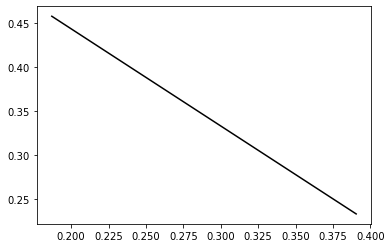

In [84]:
plt.plot(x2, EBCIRPoints,color='k')

In [86]:
EBCIRPoints[0],EBCIRPoints[9999], ApproxEBCIR(x2)

(0.45752631120695025,
 0.23298430040887225,
 array([0.45751448, 0.45749202, 0.45746956, ..., 0.23301218, 0.23298972,
        0.23296726]))

(0.1870085832617806, 0.39052671495758956)

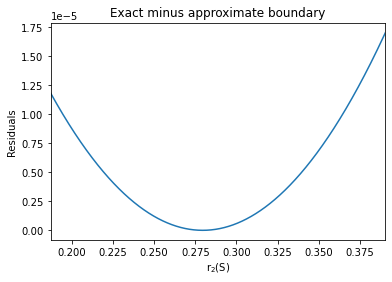

In [89]:
residualsCIR = []
for i in range(len(EBCIRPoints)):
    diff = EBCIRPoints[i]-ApproxEBCIR(x2)[i]
    residualsCIR.append(diff)
plt.plot(x2,residualsCIR)
plt.ylabel('Residuals')
plt.xlabel('r$_2$(S)')
plt.title('Exact minus approximate boundary')
plt.xlim(X_2_new.ppf((1-0.9545)/2), X_2_new.ppf((1+0.9545)/2))
#plt.ylim(-0.25*10**(-6), 1.75*10**(-6))

In [43]:
(VasSlopeTaylor1, VasSlopeTaylor2), (CIRSlopeTaylor1, CIRSlopeTaylor2)

((0.36819935552167765, 0.4348546274004361),
 (0.336719820817817, 0.41280000984494836))

In [51]:
###############################################
# CHARACTERISTIC FUNCTIONS UNDER FWD. MEASURE #
###############################################

from scipy.optimize import fsolve
from scipy.integrate import solve_ivp
from scipy.integrate import quad
import numpy as np

In [172]:
kappa1 = 0.6
theta1 = 0.4
sigma1 = 0.2
b1 = kappa1*theta1
epsilon1 = -kappa1

kappa2 = 0.5
theta2 = 0.3
sigma2 = 0.1
b2 = kappa2*theta2
epsilon2 = -kappa2

t=0
S=5
T=10
r0=0.05

def funVasicek_general(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2+(1/2)*sigma1**2*beta1**2+(1/2)*sigma2**2*beta2**2, epsilon1*beta1-1, epsilon2*beta2-1]
def funCIR_general(t, U):
    alpha, beta1, beta2 = U
    return [b1*beta1+b2*beta2, epsilon1*beta1+(1/2)*sigma1**2*beta1**2-1, epsilon2*beta2+(1/2)*sigma2**2*beta2**2-1]

def VasicekCharFuncCoeffs(init):
    t_pts = np.linspace(0, 10, 11)
    resultVasicekFwd = solve_ivp(funVasicek_general, (0, 10), init, t_eval=t_pts, method='RK45')
    return resultVasicekFwd
def CIRCharFuncCoeffs(init):
    t_pts = np.linspace(0, 10, 11)
    resultCIRFwd = solve_ivp(funCIR_general, (0, 10), init, t_eval=t_pts, method='RK45')
    return resultCIRFwd

VasicekATS = VasicekCharFuncCoeffs([0,0,0]).y[0,T-S]
VasicekB1TS = VasicekCharFuncCoeffs([0,0,0]).y[1,T-S]
VasicekB2TS = VasicekCharFuncCoeffs([0,0,0]).y[2,T-S]
VasicekATt = VasicekCharFuncCoeffs([0,0,0]).y[0,T-t]
VasicekB1Tt = VasicekCharFuncCoeffs([0,0,0]).y[1,T-t]
VasicekB2Tt = VasicekCharFuncCoeffs([0,0,0]).y[2,T-t]
CIRATS = CIRCharFuncCoeffs([0,0,0]).y[0,T-S]
CIRB1TS = CIRCharFuncCoeffs([0,0,0]).y[1,T-S]
CIRB2TS = CIRCharFuncCoeffs([0,0,0]).y[2,T-S]
CIRATt = CIRCharFuncCoeffs([0,0,0]).y[0,T-t]
CIRB1Tt = CIRCharFuncCoeffs([0,0,0]).y[1,T-t]
CIRB2Tt = CIRCharFuncCoeffs([0,0,0]).y[2,T-t]

def VasicekFwdCharFunc(z):
    b = [VasSlopeTaylor1, VasSlopeTaylor2]
    ExponentTerm1 = VasicekATS
    ExponentTerm2 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS]).y[0,S-t]
    ExponentTerm3 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS]).y[1,S-t]
    ExponentTerm4 = VasicekCharFuncCoeffs([0, 1j*z*b[0]+VasicekB1TS, 1j*z*b[1]+VasicekB2TS]).y[2,S-t]
    PtT = np.exp(VasicekATt + VasicekB1Tt*r0 + VasicekB2Tt*r0)
    return np.exp(ExponentTerm1 + ExponentTerm2 + ExponentTerm3*r0 + ExponentTerm4*r0)/PtT
def CIRFwdCharFunc(z):
    b = [CIRSlopeTaylor1, CIRSlopeTaylor2]
    ExponentTerm1 = CIRATS
    ExponentTerm2 = CIRCharFuncCoeffs([0, 1j*z*b[0]+CIRB1TS, 1j*z*b[1]+CIRB2TS]).y[0,S-t]
    ExponentTerm3 = CIRCharFuncCoeffs([0, 1j*z*b[0]+CIRB1TS, 1j*z*b[1]+CIRB2TS]).y[1,S-t]
    ExponentTerm4 = CIRCharFuncCoeffs([0, 1j*z*b[0]+CIRB1TS, 1j*z*b[1]+CIRB2TS]).y[2,S-t]
    PtT = np.exp(CIRATt + CIRB1Tt*r0 + CIRB2Tt*r0)
    return np.exp(ExponentTerm1 + ExponentTerm2 + ExponentTerm3*r0 + ExponentTerm4*r0)/PtT

def VasicekImagProbFunc(z):
    a = VasInterceptTaylor
    return np.imag(np.exp(-1j*z*a)*VasicekFwdCharFunc(z))/z
def CIRImagProbFunc(z):
    a = CIRInterceptTaylor
    return np.imag(np.exp(-1j*z*a)*CIRFwdCharFunc(z))/z

CDFVasicekFwd = 1/2 - (1/np.pi) * quad(VasicekImagProbFunc, 0, np.inf)[0]
ProbVasicekFwd = 1 - CDFVasicekFwd

CDFCIRFwd = 1/2 - (1/np.pi) * quad(CIRImagProbFunc, 0, np.inf)[0]
ProbCIRFwd = 1 - CDFCIRFwd

ProbVasicekFwd, ProbCIRFwd

(0.15801438647355903, 0.062103704498454704)

In [173]:
# (t,S,T) = (0,5,10)

ProbVasS = 0.2544556735033551
ProbVas6 = 0.20648189295481156
ProbVas7 = 0.18197678881337698
ProbVas8 = 0.1690013336556646
ProbVas9 = 0.16192630815733355
ProbVasT = 0.15801438647355903

ProbCIRS = 0.09064837327575337
ProbCIR6 = 0.07590108114820204
ProbCIR7 = 0.06861442303374399
ProbCIR8 = 0.06509946042849812
ProbCIR9 = 0.06314663650686958
ProbCIRT = 0.062103704498454704

In [174]:
VasPtS*ProbVasS-KVasicek*VasPtT6*ProbVas6-KVasicek*VasPtT7*ProbVas7-KVasicek*VasPtT8*ProbVas8-KVasicek*VasPtT9*ProbVas9-(1+KVasicek)*VasPtT*ProbVasT

0.0030638784403401245

In [175]:
CIRPtS*ProbCIRS-KCIR*CIRPtT6*ProbCIR6-KCIR*CIRPtT7*ProbCIR7-KCIR*CIRPtT8*ProbCIR8-KCIR*CIRPtT9*ProbCIR9-(1+KCIR)*CIRPtT*ProbCIRT

0.0005240881281877957